# 01 — Análise exploratória e auditoria do TrashNet

Este notebook inspeciona os dados e documenta a preparação dos seis experimentos.
Execute o preparo conforme o README antes de executar as células. Não treina modelos
nem calcula previsões de teste. As verificações são deliberadamente estritas: um erro
exige examinar os arquivos, não retirar a asserção.

**Referência:** `dataset-resized.zip`, 2.527 imagens, seis classes, 512×384 pixels.
Fonte: [TrashNet oficial](https://github.com/garythung/trashnet). As interpretações
visuais e a revisão de autoria precisam ser feitas pela equipe; consulte `GUIA_DA_EQUIPE.md`.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage

# Funciona ao iniciar Jupyter na raiz do projeto ou dentro de notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/experiments.json').is_file()
             and (p / 'src/prepare.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abra este notebook dentro da pasta trashnet do projeto.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluate import CLASSES, EXPERIMENTS, load_manifest, sha256_file
from src import visualize as vis

FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
vis.style()
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
manifest = load_manifest(ROOT)
eda = json.loads((ROOT / 'data/eda.json').read_text(encoding='utf-8'))
assert sha256_file(ROOT / 'data/manifest.csv') == eda['manifest_sha256']
assert CLASSES == eda['class_order']
print('Projeto:', ROOT.name)
print('Manifesto SHA-256:', eda['manifest_sha256'])

Projeto: trashnet
Manifesto SHA-256: 988a0a94bf617b8f3ab88e9d6da355001cb8fe2dc59f98004779bc245b9adf7f


## Contagem, divisão e integridade registrada

In [2]:
EXPECTED = pd.Series([501, 594, 403, 482, 410, 137], index=CLASSES, name='total')
counts = pd.crosstab(manifest.class_name, manifest.split).reindex(
    index=CLASSES, columns=['train', 'val', 'test'], fill_value=0)
counts['total'] = counts.sum(axis=1)
np.testing.assert_array_equal(counts['total'].to_numpy(), EXPECTED.to_numpy())
assert len(manifest) == 2527 and manifest.path.is_unique
assert manifest['split'].isin(['train', 'val', 'test']).all()
assert not eda['invalid_images']

for hash_column in ['sha256', 'pixel_sha256']:
    assert manifest.groupby(hash_column)['split'].nunique().max() == 1, (
        f'Vazamento de duplicata exata detectado: {hash_column}')

before = pd.read_csv(ROOT / 'data/manifest_before_grouping.csv')
before_counts = pd.crosstab(before.class_name, before.split).reindex(
    index=CLASSES, columns=['train', 'val', 'test'], fill_value=0)
pd.testing.assert_frame_equal(counts[['train', 'val', 'test']], before_counts)
assert set(before.path) == set(manifest.path)
pd.testing.assert_series_equal(before.set_index('path').label.sort_index(),
                               manifest.set_index('path').label.sort_index())
display(counts.rename(columns={'train':'treino', 'val':'validação', 'test':'teste'}))
split_sizes = manifest['split'].value_counts().reindex(['train', 'val', 'test'])
display(pd.DataFrame({'imagens': split_sizes, 'percentual': 100 * split_sizes / len(manifest)}))
display(pd.DataFrame({'valor': {'dimensões': eda['dimensions'], 'modos': eda['modes'],
                              'pré-processamento': eda['preprocessing'],
                              'aumento de dados': eda['augmentation']}}))
print('Contagens preservadas e hashes exatos restritos a uma única partição.')

split,treino,validação,teste,total
class_name,,,,
glass,350,75,76,501
paper,416,89,89,594
cardboard,282,61,60,403
plastic,337,72,73,482
metal,287,61,62,410
trash,96,21,20,137


,imagens,percentual
split,,
train,1768,69.964385
val,379,14.998021
test,380,15.037594


,valor
dimensões,{'512x384': 2527}
modos,{'RGB': 2527}
pré-processamento,EXIF transpose; RGB; Pillow LANCZOS a partir d...
aumento de dados,nenhum


Contagens preservadas e hashes exatos restritos a uma única partição.


## Reinspeção dos arquivos originais

Esta célula abre todos os 2.527 arquivos, verifica a decodificação e compara dimensões,
modo, SHA-256 dos bytes e SHA-256 dos pixels após EXIF/RGB com o manifesto. Não muda os dados.
A inspeção pode demorar alguns segundos e exige que as imagens tenham sido obtidas pelo preparo.

In [3]:
from PIL import Image, ImageOps

raw = ROOT / 'data/raw/dataset-resized'
issues = []
for row in manifest.itertuples(index=False):
    path = raw / row.path
    try:
        assert sha256_file(path) == row.sha256, 'bytes diferentes'
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            assert (image.width, image.height, image.mode) == (row.width, row.height, row.mode)
            rgb = ImageOps.exif_transpose(image).convert('RGB')
            pixel_hash = hashlib.sha256(np.asarray(rgb).tobytes()).hexdigest()
            assert pixel_hash == row.pixel_sha256, 'pixels diferentes'
    except Exception as exc:
        issues.append({'path': row.path, 'erro': str(exc)})
assert not issues, issues[:10]
print(f'{len(manifest)} imagens verificadas; nenhuma divergência em relação ao manifesto.')
print('Entradas auxiliares do ZIP ignoradas:', eda.get('ignored_archive_entries', []))

2527 imagens verificadas; nenhuma divergência em relação ao manifesto.
Entradas auxiliares do ZIP ignoradas: ['dataset-resized/.DS_Store', '__MACOSX/dataset-resized/._.DS_Store', '__MACOSX/dataset-resized/cardboard/._cardboard9.jpg']


## Duplicatas conflitantes: tratamento e limite

A divisão inicial usa duas chamadas estratificadas (70/30 e 50/50 do restante), ambas com
semente 42. A auditoria identifica grupos de imagens idênticas pelos hashes dos bytes e
dos pixels RGB. Um grupo não pode atravessar partições. Quando necessário, o membro é
movido para a partição da primeira linha estável do grupo e um singleton da mesma classe
faz a troca inversa. Isso preserva todos os suportes por classe e os 2.527 arquivos.

Os rótulos de origem são preservados: a correção elimina o vazamento exato, mas não elimina
ruído de anotação. Examine abaixo em quais partições os grupos ficaram. Não se verificou
independência completa por objeto, pois hashes não identificam necessariamente ângulos
diferentes de uma mesma peça. As tabelas seguintes são calculadas dos arquivos reais.

In [4]:
duplicates = manifest.loc[manifest.duplicated('pixel_sha256', keep=False)].sort_values(
    ['pixel_sha256', 'path'])
display(duplicates[['path', 'class_name', 'split', 'pixel_sha256']])
group_summary = duplicates.groupby('pixel_sha256').agg(
    arquivos=('path', 'size'), classes=('class_name', 'nunique'),
    partições=('split', 'nunique'), partição=('split', 'first'))
assert (group_summary['partições'] == 1).all()
assert len(group_summary) == eda['exact_duplicate_pixel_groups']
display(group_summary)
display(pd.DataFrame(eda['duplicate_repairs']))
print('Grupos exatos:', len(group_summary))
print('Grupos com rótulos conflitantes:', int((group_summary.classes > 1).sum()))
print('Partições dos grupos:', group_summary['partição'].value_counts().to_dict())
print(eda['near_duplicate_audit'])

,path,class_name,split,pixel_sha256
85,glass/glass176.jpg,glass,train,6939447168c001a71438496448c2b85513a3d5f1eb8b96...
1557,plastic/plastic152.jpg,plastic,train,6939447168c001a71438496448c2b85513a3d5f1eb8b96...
18,glass/glass115.jpg,glass,train,b2d08f52065ced309ba5ce64b66a8eeb65848808d08504...
2381,metal/metal91.jpg,metal,train,b2d08f52065ced309ba5ce64b66a8eeb65848808d08504...
321,glass/glass389.jpg,glass,train,c751e2644345c8376f0a511aa4e34341a779d473899d50...
1757,plastic/plastic332.jpg,plastic,train,c751e2644345c8376f0a511aa4e34341a779d473899d50...


,arquivos,classes,partições,partição
pixel_sha256,,,,
6939447168c001a71438496448c2b85513a3d5f1eb8b960fe7a7a8bf6452ab6c,2,2,1,train
b2d08f52065ced309ba5ce64b66a8eeb65848808d08504b0227665725c4e4b87,2,2,1,train
c751e2644345c8376f0a511aa4e34341a779d473899d506d05280304a3c210bc,2,2,1,train


,duplicate,singleton,original_split,grouped_split
0,plastic/plastic332.jpg,plastic/plastic1.jpg,val,train


Grupos exatos: 3
Grupos com rótulos conflitantes: 3
Partições dos grupos: {'train': 3}
Não há identificadores de objeto. Hashes evitam vazamento de duplicatas exatas; semelhança perceptual e múltiplas fotos do mesmo objeto não são totalmente controladas.


## Distribuição, exemplos e resolução

As figuras são reconstruídas pelas mesmas funções utilizadas no artigo. Os exemplos usam
apenas treino, com regra estável por caminho; não foram escolhidos segundo acertos do teste.
A ordem das classes é a do enunciado. Os painéis de resolução mostram a mesma imagem
nas três entradas, em largura × altura.

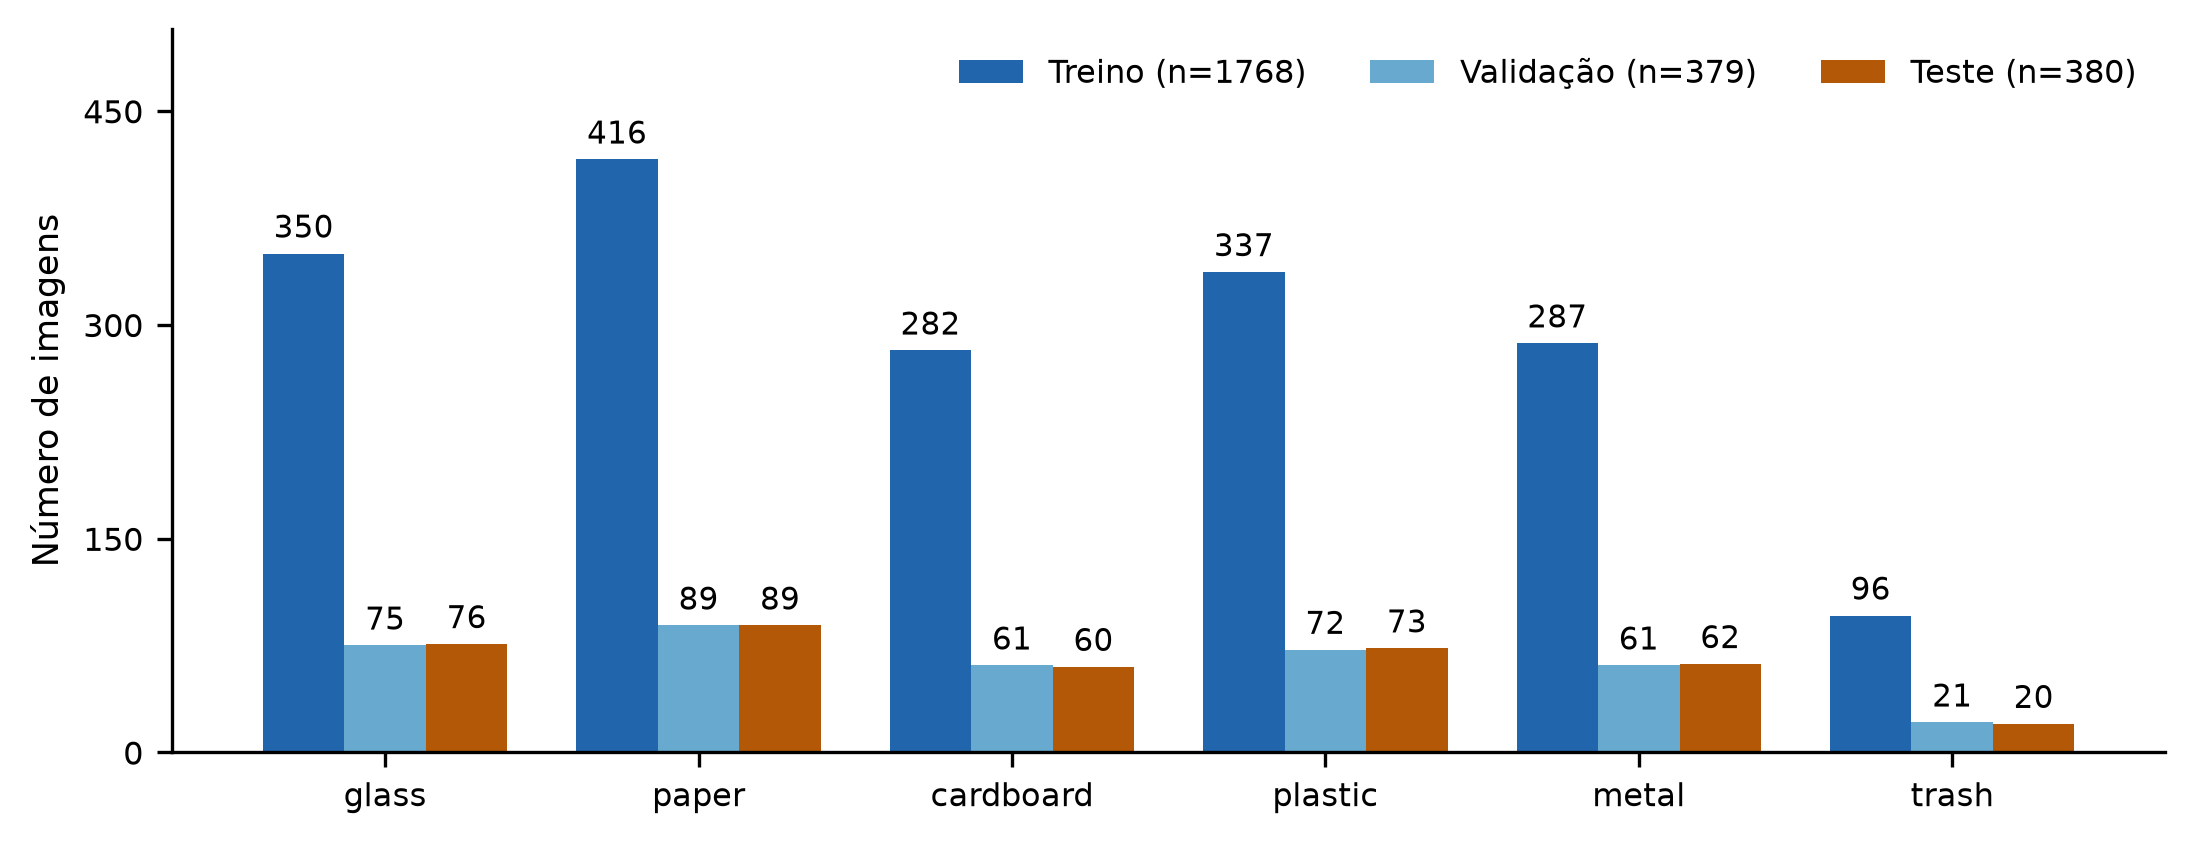

In [5]:
vis.distribution(ROOT, manifest, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig01_distribuicao.png'), width=1100))

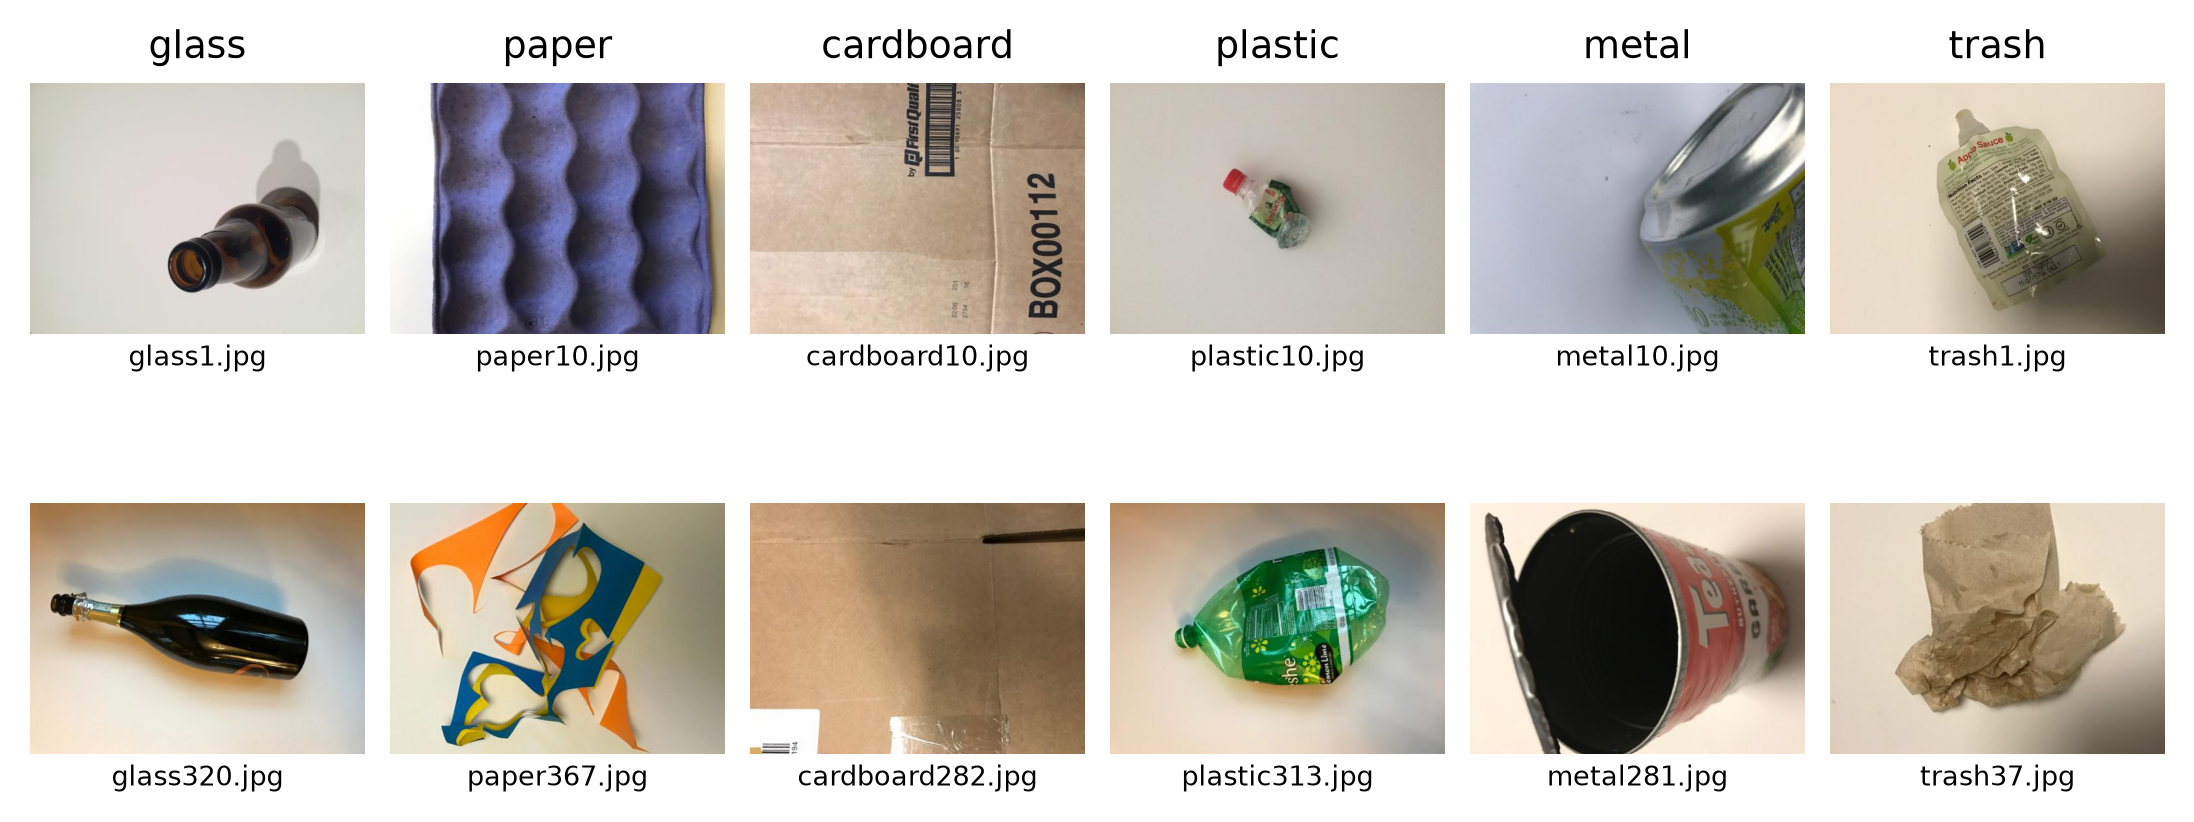

,class_name,path,split
0,glass,glass/glass1.jpg,train
1,glass,glass/glass320.jpg,train
2,paper,paper/paper10.jpg,train
3,paper,paper/paper367.jpg,train
4,cardboard,cardboard/cardboard10.jpg,train
5,cardboard,cardboard/cardboard282.jpg,train
6,plastic,plastic/plastic10.jpg,train
7,plastic,plastic/plastic313.jpg,train
8,metal,metal/metal10.jpg,train
9,metal,metal/metal281.jpg,train


In [6]:
example_records = vis.examples(ROOT, manifest, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig02_exemplos.png'), width=1100))
display(pd.DataFrame(example_records))
assert len(example_records) == 12
assert set(row['split'] for row in example_records) == {'train'}

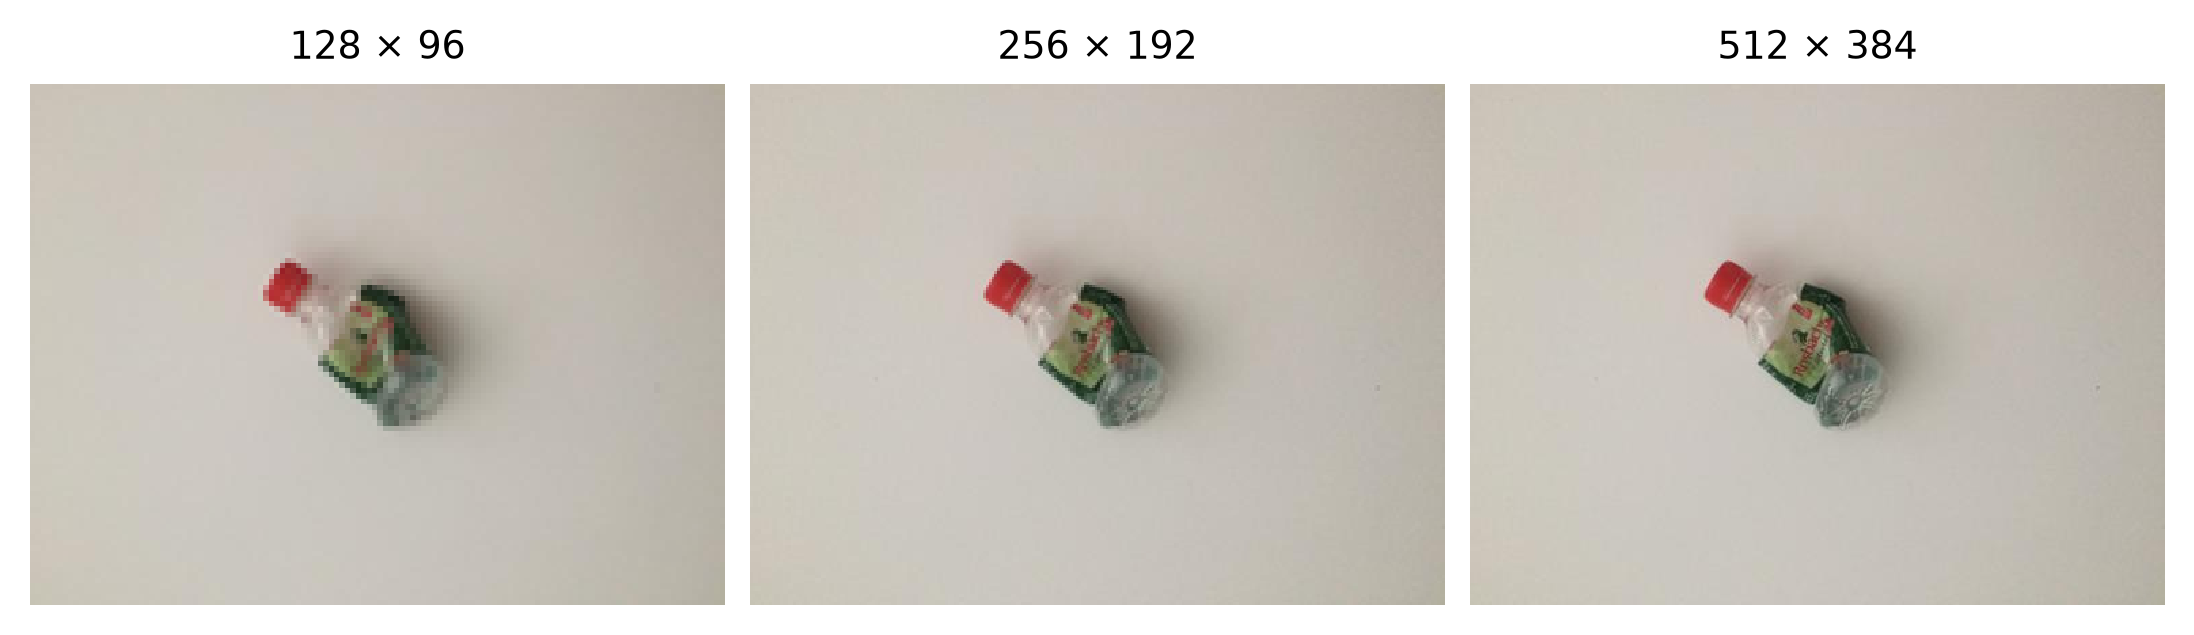

,path,split,display
0,plastic/plastic10.jpg,train,Equal physical panel size; nearest-neighbor di...


In [7]:
resolution_record = vis.resolutions(ROOT, manifest, FIGURES)
display(DisplayImage(filename=str(FIGURES / 'fig03_resolucoes.png'), width=1100))
display(pd.DataFrame([resolution_record]))

## Pesos de classe e inspeção dos caches

Os pesos inversamente proporcionais à frequência são calculados apenas sobre o treino:
$w_c=N_{treino}/(6n_{c,treino})$. Validação e teste mantêm a distribuição observada.
Não se usam as suas contagens para configurar a perda.

In [8]:
train_counts = counts['train'].to_numpy()
weights = train_counts.sum() / (len(CLASSES) * train_counts)
display(pd.DataFrame({'classe': CLASSES, 'suporte_treino': train_counts,
                      'peso_balanceado': weights}))
cache_rows = []
for width, height in [(128,96), (256,192), (512,384)]:
    folder = ROOT / 'data/cache' / f'{width}x{height}'
    cache_info = json.loads((folder / 'metadata.json').read_text())
    cache = np.load(folder / 'images.npy', mmap_mode='r', allow_pickle=False)
    assert cache.shape == (len(manifest), 3, height, width)
    assert cache.dtype == np.uint8
    assert cache_info['manifest_sha256'] == sha256_file(ROOT / 'data/manifest.csv')
    cache_rows.append({'entrada_LxA': f'{width}×{height}', 'shape_NCHW': str(cache.shape),
                       'dtype': str(cache.dtype), 'redimensionamento': cache_info['resize'],
                       'bytes_arquivo': (folder / 'images.npy').stat().st_size})
display(pd.DataFrame(cache_rows))
print('Na entrada do modelo, uint8 é convertido para float32 e dividido por 255.')

,classe,suporte_treino,peso_balanceado
0,glass,350,0.841905
1,paper,416,0.708333
2,cardboard,282,1.044917
3,plastic,337,0.874382
4,metal,287,1.026713
5,trash,96,3.069444


,entrada_LxA,shape_NCHW,dtype,redimensionamento,bytes_arquivo
0,128×96,"(2527, 3, 96, 128)",uint8,Pillow LANCZOS,93155456
1,256×192,"(2527, 3, 192, 256)",uint8,Pillow LANCZOS,372621440
2,512×384,"(2527, 3, 384, 512)",uint8,Pillow LANCZOS,1490485376


Na entrada do modelo, uint8 é convertido para float32 e dividido por 255.


## Interpretação a ser discutida pela equipe

A classe `trash` possui menos exemplos; o desempenho médio pode esconder erros nessa
categoria. Conferir os exemplos exibidos ajuda a discutir possíveis dificuldades de
material, forma, transparência, textura e rótulos. Uma hipótese visual não é uma prova
causal e precisa ser associada a uma imagem observada.

Perguntas para o registro de revisão: que problemas a auditoria encontrou? Quais tratamentos
preservaram os dados? Quais limitações continuam presentes? Como os fundos e a presença de
um objeto por fotografia limitam a aplicação em situações reais? As respostas da equipe
devem ser incorporadas ao artigo, sem substituir resultados por expectativas.